# Previsão de Cheias — Preparação dos Dados e Modelo Inicial

Este notebook prepara o dataset analítico exportado da camada Gold do sistema HidroVigilância e constrói um primeiro modelo de previsão de risco de cheia.

O problema é formulado como classificação binária:

- `target_alerta_24h = 1`: existe pelo menos uma medição com `nivel_alerta >= 1` nas próximas 24 horas, para a mesma estação e variável.
- `target_alerta_24h = 0`: não existe alerta nas próximas 24 horas.

O objetivo é prever risco futuro, não apenas classificar o estado atual.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


RANDOM_STATE = 42
DATASET_PATH = "../dados/gold_completo.csv"

OUTPUT_DIR = "../outputs/previsao"
CSV_DIR = "../outputs/previsao/csv"
FIGURES_DIR = "../outputs/previsao/figuras"

os.makedirs(CSV_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

In [2]:
def carregar_csv(path: str) -> pd.DataFrame:
    """
    Carrega o CSV tentando primeiro separador ';' e depois ','.
    """
    if not os.path.exists(path):
        raise FileNotFoundError(f"Ficheiro não encontrado: {path}")

    try:
        df = pd.read_csv(path, sep=";", low_memory=False)
        if df.shape[1] > 1:
            return df
    except Exception:
        pass

    return pd.read_csv(path, low_memory=False)


def converter_numero_robusto(series: pd.Series) -> pd.Series:
    """
    Converte valores numéricos que possam vir com vírgula decimal.
    """
    return (
        series.astype(str)
        .str.replace(",", ".", regex=False)
        .str.replace(" ", "", regex=False)
        .replace({"nan": np.nan, "None": np.nan, "": np.nan})
        .astype(float)
    )


def resumo_colunas(df: pd.DataFrame) -> pd.DataFrame:
    """
    Produz um resumo simples das colunas.
    """
    return pd.DataFrame({
        "coluna": df.columns,
        "tipo": [df[c].dtype for c in df.columns],
        "nulos": [df[c].isna().sum() for c in df.columns],
        "n_unicos": [df[c].nunique(dropna=True) for c in df.columns],
    })

In [3]:
df = carregar_csv(DATASET_PATH)

print("Dimensão inicial:", df.shape)
display(df.head())
display(resumo_colunas(df))

Dimensão inicial: (264134, 39)


,tipo_registo,id_tempo,data_hora,ano,mes,trimestre,semana,hora,estacao_ano,id_estacao,codigo_estacao,nome_estacao,tipo_estacao,id_variavel,tipo_variavel,unidade,id_localizacao,bacia,concelho,distrito,zona_risco,tipo_zona,valor_observado,nivel_alerta,variacao_valor,precipitacao_acumulada,nivel_maximo_periodo,caudal_medio_periodo,num_excedencias_limiar,duracao_horas,precipitacao_total_evento,nivel_max_evento,tempo_inicial,tempo_final,data_hora_inicio,data_hora_fim,tipo_evento,severidade,origem_evento
0,MEDICAO,2022010100,2022-01-01 00:00:00,2022,1,1,52,0,Inverno,7,11H/01A,ALBUFEIRA DA AGUIEIRA,Hidrometrica,4.0,COTA_ALBUFEIRA,m,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,117.16,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,MEDICAO,2022010101,2022-01-01 01:00:00,2022,1,1,52,1,Inverno,7,11H/01A,ALBUFEIRA DA AGUIEIRA,Hidrometrica,4.0,COTA_ALBUFEIRA,m,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,117.17,0.0,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,MEDICAO,2022010102,2022-01-01 02:00:00,2022,1,1,52,2,Inverno,7,11H/01A,ALBUFEIRA DA AGUIEIRA,Hidrometrica,4.0,COTA_ALBUFEIRA,m,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,117.18,0.0,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,MEDICAO,2022010103,2022-01-01 03:00:00,2022,1,1,52,3,Inverno,7,11H/01A,ALBUFEIRA DA AGUIEIRA,Hidrometrica,4.0,COTA_ALBUFEIRA,m,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,117.19,0.0,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,MEDICAO,2022010104,2022-01-01 04:00:00,2022,1,1,52,4,Inverno,7,11H/01A,ALBUFEIRA DA AGUIEIRA,Hidrometrica,4.0,COTA_ALBUFEIRA,m,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,117.20,0.0,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,coluna,tipo,nulos,n_unicos
0,tipo_registo,str,0,3
1,id_tempo,int64,0,49049
2,data_hora,str,0,49049
3,ano,int64,0,7
4,mes,int64,0,12
5,trimestre,int64,0,4
6,semana,int64,0,53
7,hora,int64,0,24
8,estacao_ano,str,40741,3
9,id_estacao,int64,0,6


In [4]:
# Normalizar nomes de colunas para evitar espaços acidentais
df.columns = [c.strip() for c in df.columns]

# Usar apenas registos de medições, pois o CSV é uma exportação completa da Gold
if "tipo_registo" in df.columns:
    print("Distribuição por tipo_registo:")
    display(df["tipo_registo"].value_counts(dropna=False))

    df = df[df["tipo_registo"] == "MEDICAO"].copy()
    print("Dimensão após filtrar MEDICAO:", df.shape, "-- para previsão temporal usamos apenas a Fact_Medicoes, porque é a tabela com granularidade horária.")

# Remover colunas totalmente vazias depois do filtro
df = df.dropna(axis=1, how="all").copy()

# Renomear nomes antigos, se existirem
df = df.rename(columns={
    "indicador_caudal_medio_periodo": "indicador_valor_medio_periodo",
    "caudal_medio_periodo": "indicador_valor_medio_periodo",
})

# Verificar colunas obrigatórias mínimas
colunas_obrigatorias = [
    "id_tempo",
    "codigo_estacao",
    "nome_estacao",
    "tipo_variavel",
    "valor_observado",
    "nivel_alerta",
]

faltantes = [c for c in colunas_obrigatorias if c not in df.columns]

if faltantes:
    raise ValueError(f"Colunas obrigatórias em falta no dataset: {faltantes}")

# Validar id_tempo no formato AAAAMMDDHH
df["id_tempo"] = df["id_tempo"].astype(str).str.replace(".0", "", regex=False).str.strip()

tamanho_id_tempo = df["id_tempo"].str.len().value_counts().sort_index()
print("Tamanho do id_tempo:")
display(tamanho_id_tempo)

if not df["id_tempo"].str.match(r"^\d{10}$").all():
    raise ValueError("Existem valores de id_tempo que não estão no formato AAAAMMDDHH.")

# Criar data_hora
if "data_hora" in df.columns:
    df["data_hora"] = pd.to_datetime(df["data_hora"], errors="coerce")
else:
    df["data_hora"] = pd.to_datetime(
        df["id_tempo"],
        format="%Y%m%d%H",
        errors="coerce"
    )

# Converter colunas numéricas, se existirem
numeric_cols = [
    "valor_observado",
    "variacao_valor",
    # nomes reais das colunas Gold (exclusão robusta caso os indicadores estejam presentes)
    "precipitacao_acumulada",
    "nivel_maximo_periodo",
    "caudal_medio_periodo",
    "num_excedencias_limiar",
    # nomes alternativos (compatibilidade)
    "indicador_precipitacao_acumulada",
    "indicador_nivel_maximo_periodo",
    "indicador_valor_medio_periodo",
    "indicador_num_excedencias_limiar",
    "nivel_alerta",
    "hora",
    "semana",
    "mes",
    "trimestre",
    "ano",
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = converter_numero_robusto(df[col])

df["nivel_alerta"] = df["nivel_alerta"].astype(int)

# Remover registos sem data válida
antes = len(df)
df = df.dropna(subset=["data_hora"]).copy()
depois = len(df)

print(f"Registos removidos por data inválida: {antes - depois}")
print("Dimensão após normalização:", df.shape)

print("Intervalo temporal:")
print(df["data_hora"].min(), "→", df["data_hora"].max())

display(df.head())
display(resumo_colunas(df))

Distribuição por tipo_registo:


tipo_registo
MEDICAO      263785
INDICADOR       343
EVENTO            6
Name: count, dtype: int64

Dimensão após filtrar MEDICAO: (263785, 39) -- para previsão temporal usamos apenas a Fact_Medicoes, porque é a tabela com granularidade horária.
Tamanho do id_tempo:


id_tempo
10    263785
Name: count, dtype: int64

Registos removidos por data inválida: 0
Dimensão após normalização: (263785, 25)
Intervalo temporal:
2020-10-01 00:00:00 → 2026-05-18 23:00:00


,tipo_registo,id_tempo,data_hora,ano,mes,trimestre,semana,hora,estacao_ano,id_estacao,codigo_estacao,nome_estacao,tipo_estacao,id_variavel,tipo_variavel,unidade,id_localizacao,bacia,concelho,distrito,zona_risco,tipo_zona,valor_observado,nivel_alerta,variacao_valor
0,MEDICAO,2022010100,2022-01-01 00:00:00,2022.0,1.0,1.0,52.0,0.0,Inverno,7,11H/01A,ALBUFEIRA DA AGUIEIRA,Hidrometrica,4.0,COTA_ALBUFEIRA,m,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,117.16,0,NaN
1,MEDICAO,2022010101,2022-01-01 01:00:00,2022.0,1.0,1.0,52.0,1.0,Inverno,7,11H/01A,ALBUFEIRA DA AGUIEIRA,Hidrometrica,4.0,COTA_ALBUFEIRA,m,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,117.17,0,0.01
2,MEDICAO,2022010102,2022-01-01 02:00:00,2022.0,1.0,1.0,52.0,2.0,Inverno,7,11H/01A,ALBUFEIRA DA AGUIEIRA,Hidrometrica,4.0,COTA_ALBUFEIRA,m,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,117.18,0,0.01
3,MEDICAO,2022010103,2022-01-01 03:00:00,2022.0,1.0,1.0,52.0,3.0,Inverno,7,11H/01A,ALBUFEIRA DA AGUIEIRA,Hidrometrica,4.0,COTA_ALBUFEIRA,m,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,117.19,0,0.01
4,MEDICAO,2022010104,2022-01-01 04:00:00,2022.0,1.0,1.0,52.0,4.0,Inverno,7,11H/01A,ALBUFEIRA DA AGUIEIRA,Hidrometrica,4.0,COTA_ALBUFEIRA,m,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,117.20,0,0.01


,coluna,tipo,nulos,n_unicos
0,tipo_registo,str,0,1
1,id_tempo,str,0,49049
2,data_hora,datetime64[us],0,49049
3,ano,float64,0,7
4,mes,float64,0,12
5,trimestre,float64,0,4
6,semana,float64,0,53
7,hora,float64,0,24
8,estacao_ano,str,40690,3
9,id_estacao,int64,0,6


In [50]:
# Consolidação horária
# A Gold pode conter mais do que uma medição para a mesma estação, variável e instante.
# Para modelação temporal, é necessário ter uma série com uma linha por estação + variável + hora.

chave_temporal = ["codigo_estacao", "tipo_variavel", "id_tempo"]

duplicados = df.duplicated(subset=chave_temporal, keep=False).sum()
print("Registos envolvidos em duplicados por estação + variável + id_tempo:", duplicados)

cols_contexto = [
    "data_hora",
    "nome_estacao",
    "tipo_estacao",
    "unidade",
    "id_estacao",
    "id_variavel",
    "id_localizacao",
    "bacia",
    "concelho",
    "distrito",
    "zona_risco",
    "tipo_zona",
    "ano",
    "mes",
    "trimestre",
    "semana",
    "hora",
    "estacao_ano",
]

cols_contexto = [c for c in cols_contexto if c in df.columns]

agg_dict = {
    "valor_observado": "mean",
    "nivel_alerta": "max",
}

for col in cols_contexto:
    agg_dict[col] = "first"

df = (
    df
    .groupby(chave_temporal, as_index=False, dropna=False)
    .agg(agg_dict)
)

df = df.sort_values(["codigo_estacao", "tipo_variavel", "data_hora"]).reset_index(drop=True)

# Recalcular variação após consolidação
df["variacao_valor"] = (
    df
    .groupby(["codigo_estacao", "tipo_variavel"])["valor_observado"]
    .diff()
)

print("Dimensão após consolidação horária:", df.shape)
print("Precisamos de uma única linha por estação, variável e instante -- consolidou-se fazendo média para o valor observado e máximo para o nível de alerta")
display(df.head())

Registos envolvidos em duplicados por estação + variável + id_tempo: 0
Dimensão após consolidação horária: (204527, 24)
Precisamos de uma única linha por estação, variável e instante -- consolidou-se fazendo média para o valor observado e máximo para o nível de alerta


,codigo_estacao,tipo_variavel,id_tempo,valor_observado,nivel_alerta,data_hora,nome_estacao,tipo_estacao,unidade,id_estacao,id_variavel,id_localizacao,bacia,concelho,distrito,zona_risco,tipo_zona,ano,mes,trimestre,semana,hora,estacao_ano,variacao_valor
0,11H/01A,COTA_ALBUFEIRA,2020100923,115.73,0,2020-10-09 23:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,10.0,4.0,41.0,23.0,Outono,NaN
1,11H/01A,COTA_ALBUFEIRA,2020101623,115.31,0,2020-10-16 23:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,10.0,4.0,42.0,23.0,Outono,-0.42
2,11H/01A,COTA_ALBUFEIRA,2020102323,115.67,0,2020-10-23 23:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,10.0,4.0,43.0,23.0,Outono,0.36
3,11H/01A,COTA_ALBUFEIRA,2020103023,117.01,0,2020-10-30 23:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,10.0,4.0,44.0,23.0,Outono,1.34
4,11H/01A,COTA_ALBUFEIRA,2020110623,117.44,0,2020-11-06 23:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,11.0,4.0,45.0,23.0,Outono,0.43


In [6]:
print("Dimensão:", df.shape)

print("\nPeríodo temporal:")
print(df["data_hora"].min(), "->", df["data_hora"].max())

print("\nDistribuição de nivel_alerta:")
display(df["nivel_alerta"].value_counts().sort_index())

print("\nDistribuição percentual de nivel_alerta:")
display((df["nivel_alerta"].value_counts(normalize=True).sort_index() * 100).round(2))

print("\nValores em falta:")
display(df.isna().sum().sort_values(ascending=False))

print("\nEstações:")
display(df[["codigo_estacao", "nome_estacao"]].drop_duplicates().sort_values("codigo_estacao"))

print("\nVariáveis:")
cols_variavel = [c for c in ["tipo_variavel", "unidade"] if c in df.columns]
display(df[cols_variavel].drop_duplicates().sort_values(cols_variavel))

Dimensão: (204527, 24)

Período temporal:
2020-10-01 00:00:00 -> 2026-05-18 23:00:00

Distribuição de nivel_alerta:


nivel_alerta
0    194778
1      4159
2      2677
3      2913
Name: count, dtype: int64


Distribuição percentual de nivel_alerta:


nivel_alerta
0    95.23
1     2.03
2     1.31
3     1.42
Name: proportion, dtype: float64


Valores em falta:


estacao_ano        30986
variacao_valor         6
tipo_variavel          0
hora                   0
semana                 0
trimestre              0
mes                    0
ano                    0
tipo_zona              0
zona_risco             0
distrito               0
concelho               0
codigo_estacao         0
id_localizacao         0
id_variavel            0
id_estacao             0
unidade                0
tipo_estacao           0
nome_estacao           0
data_hora              0
nivel_alerta           0
valor_observado        0
id_tempo               0
bacia                  0
dtype: int64


Estações:


,codigo_estacao,nome_estacao
0,11H/01A,ALBUFEIRA DA AGUIEIRA
16855,11K/01UG,SEIA
44622,12G/04H,PONTE SANTA CLARA COIMBRA
91755,12G/08H,PONTE CONRARIA
123478,13F/01G,SOURE
161072,13H/03UG,LOUSA



Variáveis:


,tipo_variavel,unidade
0,COTA_ALBUFEIRA,m
44622,NIVEL_HIDROMETRICO,m
16855,PRECIPITACAO,mm


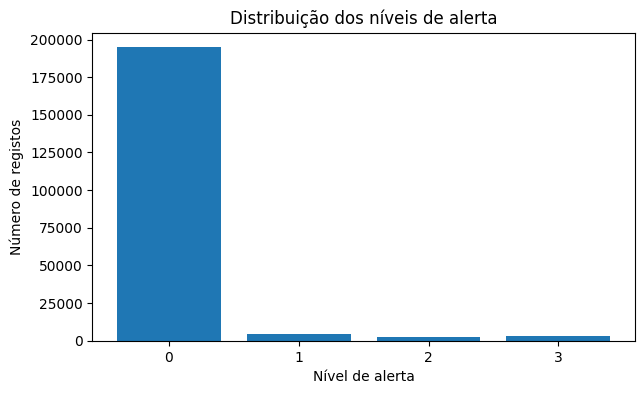

In [7]:
alert_counts = df["nivel_alerta"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(alert_counts.index.astype(str), alert_counts.values)
plt.xlabel("Nível de alerta")
plt.ylabel("Número de registos")
plt.title("Distribuição dos níveis de alerta")
plt.show()

In [8]:
df = df.sort_values(
    ["codigo_estacao", "tipo_variavel", "data_hora"]
).reset_index(drop=True)

display(df.head())

,codigo_estacao,tipo_variavel,id_tempo,valor_observado,nivel_alerta,data_hora,nome_estacao,tipo_estacao,unidade,id_estacao,id_variavel,id_localizacao,bacia,concelho,distrito,zona_risco,tipo_zona,ano,mes,trimestre,semana,hora,estacao_ano,variacao_valor
0,11H/01A,COTA_ALBUFEIRA,2020100923,115.73,0,2020-10-09 23:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,10.0,4.0,41.0,23.0,Outono,NaN
1,11H/01A,COTA_ALBUFEIRA,2020101623,115.31,0,2020-10-16 23:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,10.0,4.0,42.0,23.0,Outono,-0.42
2,11H/01A,COTA_ALBUFEIRA,2020102323,115.67,0,2020-10-23 23:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,10.0,4.0,43.0,23.0,Outono,0.36
3,11H/01A,COTA_ALBUFEIRA,2020103023,117.01,0,2020-10-30 23:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,10.0,4.0,44.0,23.0,Outono,1.34
4,11H/01A,COTA_ALBUFEIRA,2020110623,117.44,0,2020-11-06 23:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,11.0,4.0,45.0,23.0,Outono,0.43


## Criação da variável alvo 

Aqui é criada a variável que o modelo vai tentar prever: `target_alerta_24h`. 
Para cada medição, o notebook olha para as próximas 24 horas da mesma estação e da mesma variável. Se nesse período existir pelo menos uma medição futura com `nivel_alerta >= 1`, então: `target_alerta_24h = 1` Caso contrário: `target_alerta_24h = 0` 

O ponto mais importante é que o target é calculado olhando apenas para o futuro da mesma série temporal. Ou seja, não mistura estações diferentes nem variáveis diferentes.

In [9]:
def criar_target_futuro(
    data: pd.DataFrame,
    group_cols: list[str],
    time_col: str,
    alert_col: str,
    horizon_hours: int = 24,
    threshold: int = 1,
) -> pd.DataFrame:
    """
    Cria uma variável alvo futura.

    Para cada linha, olha para as próximas `horizon_hours` dentro do mesmo grupo.
    O target é 1 se existir pelo menos uma observação futura com alert_col >= threshold.
    A observação atual é excluída do cálculo para evitar leakage.
    """
    partes = []

    for _, g in data.groupby(group_cols, sort=False):
        g = g.sort_values(time_col).copy()

        tempos = g[time_col].to_numpy()
        alertas = g[alert_col].to_numpy()

        future_max = np.full(len(g), np.nan)

        for i in range(len(g)):
            limite = tempos[i] + np.timedelta64(horizon_hours, "h")
            fim = np.searchsorted(tempos, limite, side="right")

            # Exclui a própria linha. Só considera observações futuras.
            if i + 1 < fim:
                future_max[i] = np.max(alertas[i + 1:fim])

        g[f"max_alerta_prox_{horizon_hours}h"] = future_max
        g[f"target_alerta_{horizon_hours}h"] = np.where(
            np.isnan(future_max),
            np.nan,
            (future_max >= threshold).astype(int)
        )

        partes.append(g)

    return pd.concat(partes, ignore_index=True)


df_model = criar_target_futuro(
    data=df,
    group_cols=["codigo_estacao", "tipo_variavel"],
    time_col="data_hora",
    alert_col="nivel_alerta",
    horizon_hours=24,
    threshold=1,
)

df_model = df_model.dropna(subset=["target_alerta_24h"]).copy()
df_model["target_alerta_24h"] = df_model["target_alerta_24h"].astype(int)

print("Dimensão após criação do target:", df_model.shape)

print("\nDistribuição absoluta do target:")
display(df_model["target_alerta_24h"].value_counts().sort_index())

print("\nDistribuição percentual do target:")
display((df_model["target_alerta_24h"].value_counts(normalize=True).sort_index() * 100).round(2))

Dimensão após criação do target: (204268, 26)

Distribuição absoluta do target:


target_alerta_24h
0    189385
1     14883
Name: count, dtype: int64


Distribuição percentual do target:


target_alerta_24h
0    92.71
1     7.29
Name: proportion, dtype: float64

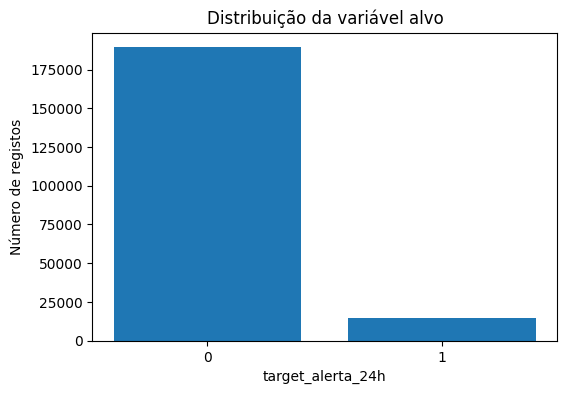

In [10]:
target_counts = df_model["target_alerta_24h"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(target_counts.index.astype(str), target_counts.values)
plt.xlabel("target_alerta_24h")
plt.ylabel("Número de registos")
plt.title("Distribuição da variável alvo")
plt.show()

###  Target de previsão 

Neste ponto, o problema deixa de ser apenas descritivo e passa a ser preditivo. Cada linha deixa de representar apenas uma medição observada e passa a ter também uma pergunta associada: "vai existir alerta nas próximas 24 horas para esta estação e variável?" 

A distribuição mostra que os casos positivos são minoritários. Isto é esperado, porque a maioria das medições ocorre em períodos normais. Esta observação justifica a escolha de métricas como recall e F1-score em vez de usar apenas accuracy.

---

## Feature engineering

Nesta parte são criadas variáveis explicativas para ajudar o modelo a prever o alerta futuro.

Há três tipos principais de features:

1. **atributos temporais**, como dia do mês, dia da semana, fim de semana, hora e mês;
2. **codificação cíclica da hora e do mês**, usando seno e cosseno;
3. **histórico recente da variável**, através de lags, médias móveis e máximos móveis.

A codificação cíclica é usada porque hora e mês têm comportamento circular. Por exemplo, a hora 23 e a hora 0 estão próximas no tempo, mas numericamente parecem distantes.

Os lags e estatísticas móveis permitem representar a evolução recente da estação e variável. Isto é importante porque, em hidrologia, a tendência recente pode ser mais informativa do que uma medição isolada.

In [11]:
df_model["dia_mes"] = df_model["data_hora"].dt.day
df_model["dia_semana"] = df_model["data_hora"].dt.dayofweek
df_model["fim_semana"] = df_model["dia_semana"].isin([5, 6]).astype(int)

# Representação cíclica de hora e mês
df_model["hora_sin"] = np.sin(2 * np.pi * df_model["hora"] / 24) if "hora" in df_model.columns else np.sin(2 * np.pi * df_model["data_hora"].dt.hour / 24)
df_model["hora_cos"] = np.cos(2 * np.pi * df_model["hora"] / 24) if "hora" in df_model.columns else np.cos(2 * np.pi * df_model["data_hora"].dt.hour / 24)

if "mes" in df_model.columns:
    df_model["mes_sin"] = np.sin(2 * np.pi * df_model["mes"] / 12)
    df_model["mes_cos"] = np.cos(2 * np.pi * df_model["mes"] / 12)
else:
    df_model["mes_sin"] = np.sin(2 * np.pi * df_model["data_hora"].dt.month / 12)
    df_model["mes_cos"] = np.cos(2 * np.pi * df_model["data_hora"].dt.month / 12)

display(df_model.head())

,codigo_estacao,tipo_variavel,id_tempo,valor_observado,nivel_alerta,data_hora,nome_estacao,tipo_estacao,unidade,id_estacao,id_variavel,id_localizacao,bacia,concelho,distrito,zona_risco,tipo_zona,ano,mes,trimestre,semana,hora,estacao_ano,variacao_valor,max_alerta_prox_24h,target_alerta_24h,dia_mes,dia_semana,fim_semana,hora_sin,hora_cos,mes_sin,mes_cos
8,11H/01A,COTA_ALBUFEIRA,2020113023,116.80,0,2020-11-30 23:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,11.0,4.0,49.0,23.0,Outono,0.25,0.0,0,30,0,0,-0.258819,0.965926,-5.000000e-01,0.866025
9,11H/01A,COTA_ALBUFEIRA,2020120100,116.76,0,2020-12-01 00:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,12.0,4.0,49.0,0.0,Inverno,-0.04,0.0,0,1,1,0,0.000000,1.000000,-2.449294e-16,1.000000
10,11H/01A,COTA_ALBUFEIRA,2020120101,116.77,0,2020-12-01 01:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,12.0,4.0,49.0,1.0,Inverno,0.01,0.0,0,1,1,0,0.258819,0.965926,-2.449294e-16,1.000000
11,11H/01A,COTA_ALBUFEIRA,2020120102,116.79,0,2020-12-01 02:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,12.0,4.0,49.0,2.0,Inverno,0.02,0.0,0,1,1,0,0.500000,0.866025,-2.449294e-16,1.000000
12,11H/01A,COTA_ALBUFEIRA,2020120103,116.82,0,2020-12-01 03:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,12.0,4.0,49.0,3.0,Inverno,0.03,0.0,0,1,1,0,0.707107,0.707107,-2.449294e-16,1.000000


## Lags, médias móveis e máximos móveis

Aqui são criadas features baseadas no passado recente da própria série temporal.

Exemplos:

- `valor_observado_lag_1h`: valor observado uma hora antes;
- `valor_observado_lag_6h`: valor observado seis horas antes;
- `valor_observado_media_movel_3h`: média das últimas horas;
- `valor_observado_max_movel_6h`: máximo recente.

Estas features são calculadas por estação e variável. Assim, o passado da precipitação numa estação não é misturado com o passado do nível hidrométrico noutra estação.



In [12]:
def adicionar_features_temporais(
    data: pd.DataFrame,
    group_cols: list[str],
    value_col: str = "valor_observado",
    lags: list[int] = [1, 3, 6, 12, 24],
    windows: list[int] = [3, 6, 12, 24],
) -> pd.DataFrame:
    """
    Cria lags e estatísticas móveis usando apenas valores passados.

    As médias e máximos móveis usam shift(1), logo não incluem a observação atual.
    Isto evita data leakage.
    """
    data = data.sort_values(group_cols + ["data_hora"]).copy()

    grouped = data.groupby(group_cols, group_keys=False)

    # Lags
    for lag in lags:
        data[f"{value_col}_lag_{lag}h"] = grouped[value_col].shift(lag)

    # Médias e máximos móveis por grupo
    for window in windows:
        data[f"{value_col}_media_movel_{window}h"] = grouped[value_col].transform(
            lambda s: s.shift(1).rolling(window=window, min_periods=1).mean()
        )

        data[f"{value_col}_max_movel_{window}h"] = grouped[value_col].transform(
            lambda s: s.shift(1).rolling(window=window, min_periods=1).max()
        )

    return data


df_model = adicionar_features_temporais(
    data=df_model,
    group_cols=["codigo_estacao", "tipo_variavel"],
    value_col="valor_observado",
)

# Lag da variação, se existir
if "variacao_valor" in df_model.columns:
    df_model["variacao_valor_lag_1h"] = (
        df_model
        .groupby(["codigo_estacao", "tipo_variavel"])["variacao_valor"]
        .shift(1)
    )

print("Dimensão após features temporais:", df_model.shape)
display(df_model.head())

Dimensão após features temporais: (204268, 47)


,codigo_estacao,tipo_variavel,id_tempo,valor_observado,nivel_alerta,data_hora,nome_estacao,tipo_estacao,unidade,id_estacao,id_variavel,id_localizacao,bacia,concelho,distrito,zona_risco,tipo_zona,ano,mes,trimestre,semana,hora,estacao_ano,variacao_valor,max_alerta_prox_24h,target_alerta_24h,dia_mes,dia_semana,fim_semana,hora_sin,hora_cos,mes_sin,mes_cos,valor_observado_lag_1h,valor_observado_lag_3h,valor_observado_lag_6h,valor_observado_lag_12h,valor_observado_lag_24h,valor_observado_media_movel_3h,valor_observado_max_movel_3h,valor_observado_media_movel_6h,valor_observado_max_movel_6h,valor_observado_media_movel_12h,valor_observado_max_movel_12h,valor_observado_media_movel_24h,valor_observado_max_movel_24h,variacao_valor_lag_1h
8,11H/01A,COTA_ALBUFEIRA,2020113023,116.80,0,2020-11-30 23:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,11.0,4.0,49.0,23.0,Outono,0.25,0.0,0,30,0,0,-0.258819,0.965926,-5.000000e-01,0.866025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,11H/01A,COTA_ALBUFEIRA,2020120100,116.76,0,2020-12-01 00:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,12.0,4.0,49.0,0.0,Inverno,-0.04,0.0,0,1,1,0,0.000000,1.000000,-2.449294e-16,1.000000,116.80,NaN,NaN,NaN,NaN,116.800000,116.80,116.800000,116.8,116.800000,116.8,116.800000,116.8,0.25
10,11H/01A,COTA_ALBUFEIRA,2020120101,116.77,0,2020-12-01 01:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,12.0,4.0,49.0,1.0,Inverno,0.01,0.0,0,1,1,0,0.258819,0.965926,-2.449294e-16,1.000000,116.76,NaN,NaN,NaN,NaN,116.780000,116.80,116.780000,116.8,116.780000,116.8,116.780000,116.8,-0.04
11,11H/01A,COTA_ALBUFEIRA,2020120102,116.79,0,2020-12-01 02:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,12.0,4.0,49.0,2.0,Inverno,0.02,0.0,0,1,1,0,0.500000,0.866025,-2.449294e-16,1.000000,116.77,116.80,NaN,NaN,NaN,116.776667,116.80,116.776667,116.8,116.776667,116.8,116.776667,116.8,0.01
12,11H/01A,COTA_ALBUFEIRA,2020120103,116.82,0,2020-12-01 03:00:00,ALBUFEIRA DA AGUIEIRA,Hidrometrica,m,7,4.0,11,Mondego,Penacova,Coimbra,Media,Montante/Albufeira,2020.0,12.0,4.0,49.0,3.0,Inverno,0.03,0.0,0,1,1,0,0.707107,0.707107,-2.449294e-16,1.000000,116.79,116.76,NaN,NaN,NaN,116.773333,116.79,116.780000,116.8,116.780000,116.8,116.780000,116.8,0.02


### Informação usada pelo modelo

Depois do feature engineering, o modelo já não usa apenas o valor observado no instante atual.

Passa a usar também o comportamento recente da mesma estação e variável: valores anteriores, médias recentes e máximos recentes.

Isto é importante porque, no contexto hidrológico, a evolução recente é mais informativa do que uma medição isolada. Uma subida gradual ou um valor máximo recente podem indicar aproximação a uma situação de alerta.

---

##  Colunas excluídas e prevenção de data leakage

Antes de treinar os modelos, são removidas colunas que não devem ser usadas como variáveis explicativas.

São removidas, por exemplo:

- `target_alerta_24h`, porque é aquilo que queremos prever;
- `max_alerta_prox_24h`, porque contém informação futura;
- `data_hora` e `id_tempo`, porque são usados para ordenação e split temporal;
- `nivel_alerta`, porque é uma classificação operacional calculada a partir dos limiares atuais.

Esta decisão reduz o risco de data leakage. O objetivo é que o modelo aprenda padrões a partir dos valores observados, histórico recente e contexto, e não a partir de informação futura ou da própria regra de alerta.

In [13]:
cols_excluir = [
    # Alvo e derivados futuros
    "target_alerta_24h",
    "max_alerta_prox_24h",

    # Informação temporal bruta usada para ordenação/split
    "id_tempo",
    "data_hora",

    # Estado atual calculado diretamente por limiares.
    # Excluído para evitar que o modelo aprenda apenas a regra operacional atual.
    "nivel_alerta",

    # Indicadores mensais.
    # Excluídos no primeiro modelo para reduzir risco de leakage,
    # pois podem conter informação agregada do próprio mês.
    # nomes reais das colunas Gold (exclusão robusta caso os indicadores estejam presentes)
    "precipitacao_acumulada",
    "nivel_maximo_periodo",
    "caudal_medio_periodo",
    "num_excedencias_limiar",
    # nomes alternativos (compatibilidade)
    "indicador_precipitacao_acumulada",
    "indicador_nivel_maximo_periodo",
    "indicador_valor_medio_periodo",
    "indicador_num_excedencias_limiar",
]

cols_excluir = [c for c in cols_excluir if c in df_model.columns]

feature_cols = [c for c in df_model.columns if c not in cols_excluir]

print("Colunas excluídas:")
display(cols_excluir)

print("\nNúmero de features candidatas:", len(feature_cols))
display(feature_cols)

Colunas excluídas:


['target_alerta_24h',
 'max_alerta_prox_24h',
 'id_tempo',
 'data_hora',
 'nivel_alerta']


Número de features candidatas: 42


['codigo_estacao',
 'tipo_variavel',
 'valor_observado',
 'nome_estacao',
 'tipo_estacao',
 'unidade',
 'id_estacao',
 'id_variavel',
 'id_localizacao',
 'bacia',
 'concelho',
 'distrito',
 'zona_risco',
 'tipo_zona',
 'ano',
 'mes',
 'trimestre',
 'semana',
 'hora',
 'estacao_ano',
 'variacao_valor',
 'dia_mes',
 'dia_semana',
 'fim_semana',
 'hora_sin',
 'hora_cos',
 'mes_sin',
 'mes_cos',
 'valor_observado_lag_1h',
 'valor_observado_lag_3h',
 'valor_observado_lag_6h',
 'valor_observado_lag_12h',
 'valor_observado_lag_24h',
 'valor_observado_media_movel_3h',
 'valor_observado_max_movel_3h',
 'valor_observado_media_movel_6h',
 'valor_observado_max_movel_6h',
 'valor_observado_media_movel_12h',
 'valor_observado_max_movel_12h',
 'valor_observado_media_movel_24h',
 'valor_observado_max_movel_24h',
 'variacao_valor_lag_1h']


---

## Separação temporal entre treino e teste

Como os dados são temporais, a separação treino/teste não deve ser aleatória.

O notebook usa os primeiros 80% do período para treino e os últimos 20% para teste. Isto simula melhor uma situação real: treinar com dados do passado e avaliar em dados posteriores.

**Se fosse usado um split aleatório, o treino poderia conter observações do futuro relativamente ao teste. Isso tornaria a avaliação demasiado otimista.**


In [14]:
# Split temporal: primeiros 80% do período para treino, últimos 20% para teste
datas_ordenadas = np.sort(df_model["data_hora"].unique())
cutoff_idx = int(len(datas_ordenadas) * 0.80)
cutoff_date = datas_ordenadas[cutoff_idx]

train_df = df_model[df_model["data_hora"] < cutoff_date].copy()
test_df = df_model[df_model["data_hora"] >= cutoff_date].copy()

X_train = train_df[feature_cols].copy()
y_train = train_df["target_alerta_24h"].copy()

X_test = test_df[feature_cols].copy()
y_test = test_df["target_alerta_24h"].copy()

print("Data de corte:", cutoff_date)
print("Treino:", X_train.shape, "Teste:", X_test.shape)

print("\nDistribuição do alvo no treino:")
display(y_train.value_counts(normalize=False).sort_index())
display((y_train.value_counts(normalize=True).sort_index() * 100).round(2))

print("\nDistribuição do alvo no teste:")
display(y_test.value_counts(normalize=False).sort_index())
display((y_test.value_counts(normalize=True).sort_index() * 100).round(2))

Data de corte: 2025-03-23T18:00:00.000000
Treino: (176096, 42) Teste: (28172, 42)

Distribuição do alvo no treino:


target_alerta_24h
0    165324
1     10772
Name: count, dtype: int64

target_alerta_24h
0    93.88
1     6.12
Name: proportion, dtype: float64


Distribuição do alvo no teste:


target_alerta_24h
0    24061
1     4111
Name: count, dtype: int64

target_alerta_24h
0    85.41
1    14.59
Name: proportion, dtype: float64

In [15]:
numeric_features = X_train.select_dtypes(include=["int64", "int32", "float64", "float32"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Features numéricas:", len(numeric_features))
display(numeric_features)

print("\nFeatures categóricas:", len(categorical_features))
display(categorical_features)

Features numéricas: 31


/var/folders/_h/_pwmhsdx6cq6yj6lwr5xpmvc0000gn/T/ipykernel_44137/2596336482.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


['valor_observado',
 'id_estacao',
 'id_variavel',
 'id_localizacao',
 'ano',
 'mes',
 'trimestre',
 'semana',
 'hora',
 'variacao_valor',
 'dia_mes',
 'dia_semana',
 'fim_semana',
 'hora_sin',
 'hora_cos',
 'mes_sin',
 'mes_cos',
 'valor_observado_lag_1h',
 'valor_observado_lag_3h',
 'valor_observado_lag_6h',
 'valor_observado_lag_12h',
 'valor_observado_lag_24h',
 'valor_observado_media_movel_3h',
 'valor_observado_max_movel_3h',
 'valor_observado_media_movel_6h',
 'valor_observado_max_movel_6h',
 'valor_observado_media_movel_12h',
 'valor_observado_max_movel_12h',
 'valor_observado_media_movel_24h',
 'valor_observado_max_movel_24h',
 'variacao_valor_lag_1h']


Features categóricas: 11


['codigo_estacao',
 'tipo_variavel',
 'nome_estacao',
 'tipo_estacao',
 'unidade',
 'bacia',
 'concelho',
 'distrito',
 'zona_risco',
 'tipo_zona',
 'estacao_ano']


---

## Pré-processamento das features

Nesta fase são preparados os dados para os modelos.

As variáveis numéricas passam por:

- **imputação pela mediana**, para tratar valores em falta;
- **normalização**, útil sobretudo para modelos como regressão logística.

As variáveis categóricas passam por:

- **imputação pelo valor mais frequente**;
- **one-hot encoding**, para transformar categorias textuais em colunas numéricas.

Este pré-processamento é integrado num pipeline, garantindo que as mesmas transformações são aplicadas ao treino e ao teste.

In [16]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ],
    remainder="drop",
)

## Modelos avaliados

São avaliados quatro modelos:

- **baseline com classe maioritária**;
- **regressão logística**;
- **árvore de decisão**;
- **Random Forest**.

O baseline serve como comparação mínima. Como a classe maioritária é "sem alerta", este modelo tende a prever sempre ausência de alerta.

A regressão logística é um modelo simples e interpretável. 
A árvore de decisão permite regras não lineares. 
A Random Forest combina várias árvores e tende a ser mais robusta em dados tabulares.

In [17]:
def avaliar_modelo(nome: str, model, X_test, y_test) -> dict:
    """
    Avalia um modelo de classificação binária.
    """
    y_pred = model.predict(X_test)

    resultados = {
        "modelo": nome,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
    }

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]

        try:
            resultados["roc_auc"] = roc_auc_score(y_test, y_score)
        except Exception:
            resultados["roc_auc"] = np.nan

        try:
            resultados["average_precision"] = average_precision_score(y_test, y_score)
        except Exception:
            resultados["average_precision"] = np.nan
    else:
        resultados["roc_auc"] = np.nan
        resultados["average_precision"] = np.nan

    print(f"\n===== {nome} =====")
    print(classification_report(y_test, y_pred, zero_division=0))

    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot()
    plt.title(f"Matriz de confusão — {nome}")
    plt.show()

    return resultados


===== Baseline — classe maioritária =====
              precision    recall  f1-score   support

           0       0.85      1.00      0.92     24061
           1       0.00      0.00      0.00      4111

    accuracy                           0.85     28172
   macro avg       0.43      0.50      0.46     28172
weighted avg       0.73      0.85      0.79     28172



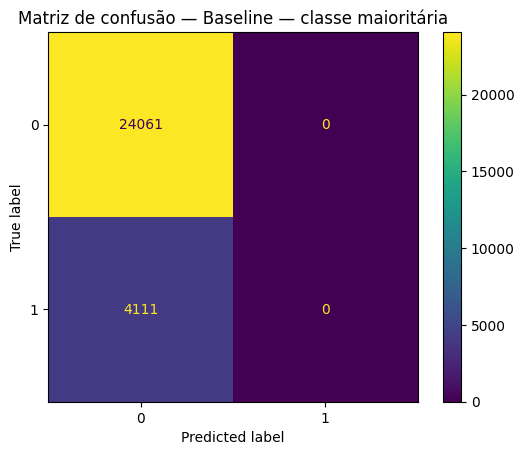

In [18]:
baseline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent")),
])

baseline.fit(X_train, y_train)

resultados = []
resultados.append(avaliar_modelo("Baseline — classe maioritária", baseline, X_test, y_test))


===== Regressão Logística =====
              precision    recall  f1-score   support

           0       0.98      0.87      0.92     24061
           1       0.53      0.89      0.66      4111

    accuracy                           0.87     28172
   macro avg       0.76      0.88      0.79     28172
weighted avg       0.91      0.87      0.88     28172



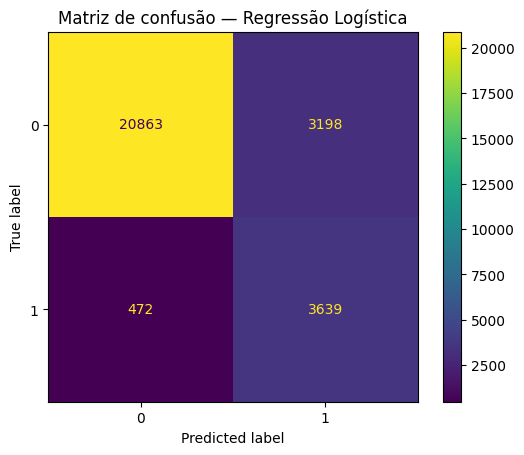

In [19]:
log_reg = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
])

log_reg.fit(X_train, y_train)

resultados.append(avaliar_modelo("Regressão Logística", log_reg, X_test, y_test))


===== Árvore de Decisão =====
              precision    recall  f1-score   support

           0       0.96      0.49      0.65     24061
           1       0.23      0.89      0.37      4111

    accuracy                           0.55     28172
   macro avg       0.60      0.69      0.51     28172
weighted avg       0.86      0.55      0.61     28172



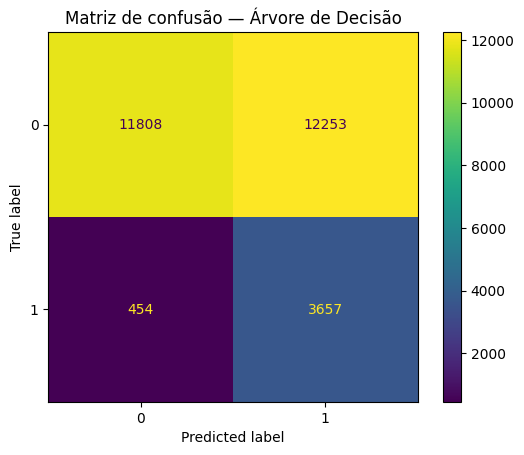

In [20]:
decision_tree = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=50,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
])

decision_tree.fit(X_train, y_train)

resultados.append(avaliar_modelo("Árvore de Decisão", decision_tree, X_test, y_test))


===== Random Forest =====
              precision    recall  f1-score   support

           0       0.97      0.91      0.94     24061
           1       0.63      0.86      0.73      4111

    accuracy                           0.91     28172
   macro avg       0.80      0.89      0.84     28172
weighted avg       0.92      0.91      0.91     28172



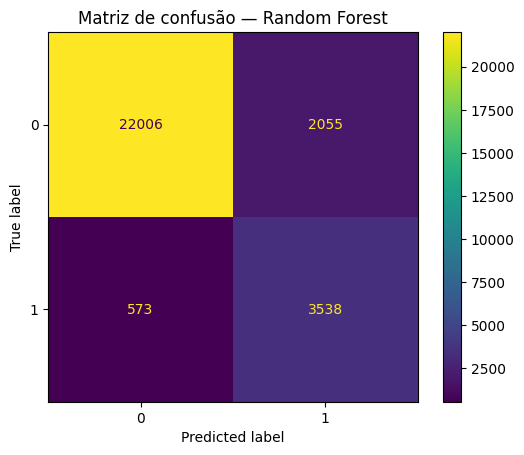

In [21]:
random_forest = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=25,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )),
])

random_forest.fit(X_train, y_train)

resultados.append(avaliar_modelo("Random Forest", random_forest, X_test, y_test))

In [22]:
resultados_df = pd.DataFrame(resultados)
resultados_df = resultados_df.sort_values("f1", ascending=False)

display(resultados_df.round(4))

,modelo,accuracy,precision,recall,f1,roc_auc,average_precision
3,Random Forest,0.9067,0.6326,0.8606,0.7292,0.9567,0.9064
1,Regressão Logística,0.8697,0.5323,0.8852,0.6648,0.9342,0.8927
2,Árvore de Decisão,0.5489,0.2299,0.8896,0.3653,0.9021,0.8660
0,Baseline — classe maioritária,0.8541,0.0000,0.0000,0.0000,0.5000,0.1459


### Primeira experiência

A primeira experiência mostra que existe sinal preditivo nos dados da Gold.

O baseline serve como referência mínima e tem mau desempenho na deteção de alertas, porque tende a prever a classe maioritária.

A Random Forest apresenta o melhor F1-score nesta experiência, indicando melhor equilíbrio entre detetar alertas e evitar falsos alarmes. Mesmo assim, esta experiência ainda mistura todas as variáveis, incluindo precipitação, nível hidrométrico e cota de albufeira.

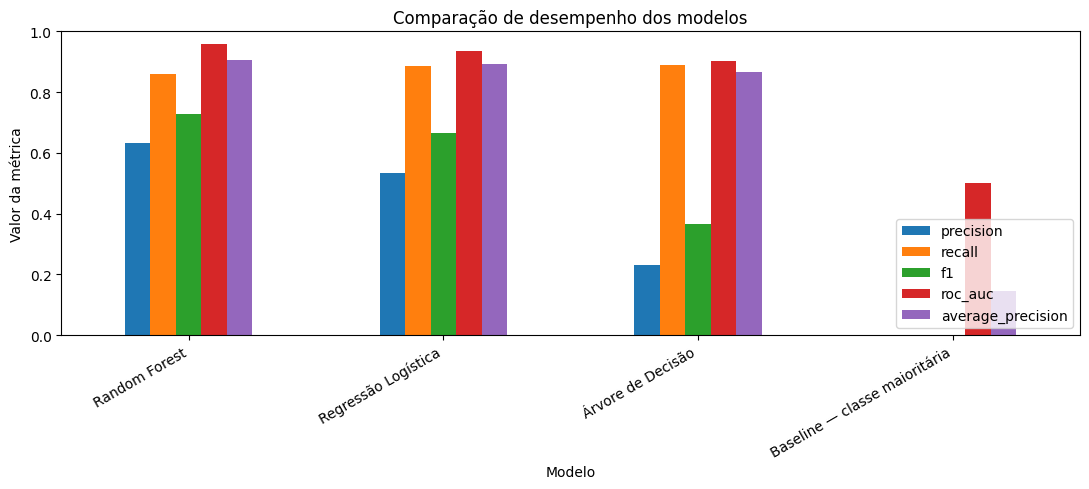

In [23]:
metricas_plot = ["precision", "recall", "f1", "roc_auc", "average_precision"]

plot_df = resultados_df.set_index("modelo")[metricas_plot]

plot_df.plot(kind="bar", figsize=(11, 5))
plt.title("Comparação de desempenho dos modelos")
plt.ylabel("Valor da métrica")
plt.xlabel("Modelo")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

,feature,importance
0,valor_observado,0.564778
29,valor_observado_max_movel_24h,0.173189
33,codigo_estacao_12G/04H,0.099169
24,valor_observado_media_movel_6h,0.063435
7,semana,0.029446
4,ano,0.026985
48,unidade_m,0.015614
15,mes_sin,0.009840
10,dia_mes,0.005223
30,variacao_valor_lag_1h,0.004933


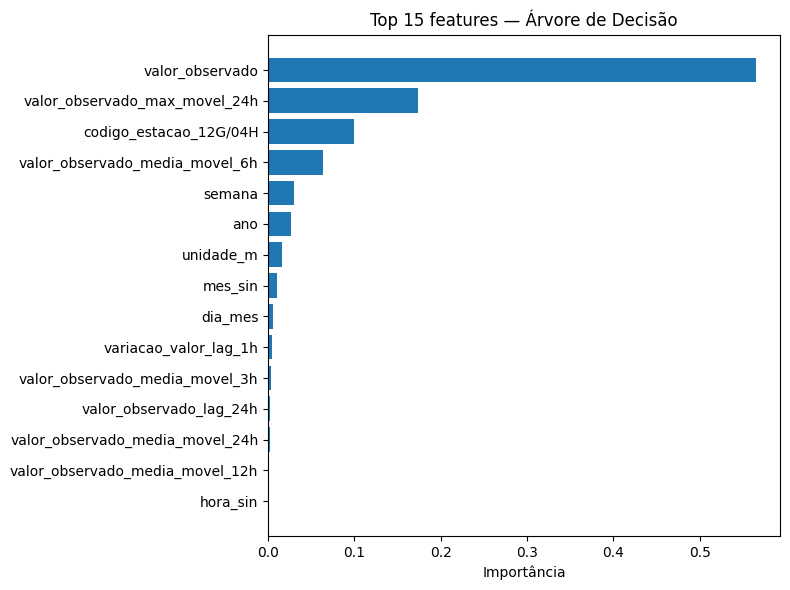

In [24]:
def obter_nomes_features(preprocessor: ColumnTransformer) -> list[str]:
    nomes = []

    if numeric_features:
        nomes.extend(numeric_features)

    if categorical_features:
        onehot = preprocessor.named_transformers_["cat"].named_steps["onehot"]
        cat_names = onehot.get_feature_names_out(categorical_features).tolist()
        nomes.extend(cat_names)

    return nomes


tree_preprocessor = decision_tree.named_steps["preprocessor"]
tree_classifier = decision_tree.named_steps["classifier"]

feature_names = obter_nomes_features(tree_preprocessor)
importances = tree_classifier.feature_importances_

importancias_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances,
}).sort_values("importance", ascending=False)

display(importancias_df.head(20))

top_importancias = importancias_df.head(15).sort_values("importance")

plt.figure(figsize=(8, 6))
plt.barh(top_importancias["feature"], top_importancias["importance"])
plt.xlabel("Importância")
plt.title("Top 15 features — Árvore de Decisão")
plt.tight_layout()
plt.show()

In [25]:
melhor_nome = resultados_df.iloc[0]["modelo"]

modelos = {
    "Baseline — classe maioritária": baseline,
    "Regressão Logística": log_reg,
    "Árvore de Decisão": decision_tree,
    "Random Forest": random_forest,
}

melhor_modelo = modelos[melhor_nome]

print("Melhor modelo segundo F1:", melhor_nome)

predicoes_df = test_df.copy()
predicoes_df["pred_target_alerta_24h"] = melhor_modelo.predict(X_test)

if hasattr(melhor_modelo, "predict_proba"):
    predicoes_df["prob_alerta_24h"] = melhor_modelo.predict_proba(X_test)[:, 1]
else:
    predicoes_df["prob_alerta_24h"] = np.nan

display(
    predicoes_df[
        [
            "data_hora",
            "codigo_estacao",
            "nome_estacao",
            "tipo_variavel",
            "valor_observado",
            "target_alerta_24h",
            "pred_target_alerta_24h",
            "prob_alerta_24h",
        ]
    ].head(20)
)

Melhor modelo segundo F1: Random Forest


,data_hora,codigo_estacao,nome_estacao,tipo_variavel,valor_observado,target_alerta_24h,pred_target_alerta_24h,prob_alerta_24h
14322,2025-03-23 18:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,122.40,1,1,0.999953
14323,2025-03-23 19:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,122.43,1,1,0.999896
14324,2025-03-23 20:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,122.40,1,1,0.999896
14325,2025-03-23 21:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,122.35,1,1,0.999893
14326,2025-03-23 22:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,122.33,1,1,0.999943
14327,2025-03-23 23:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,122.33,1,1,0.999943
14328,2025-03-24 00:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,122.35,1,1,1.000000
14329,2025-03-24 01:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,122.40,1,1,1.000000
14330,2025-03-24 02:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,122.45,1,1,1.000000
14331,2025-03-24 03:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,122.50,1,1,1.000000


In [26]:
os.makedirs(CSV_DIR, exist_ok=True)

resultados_df.to_csv(
    f"{CSV_DIR}/resultados_modelos_previsao_24h.csv",
    index=False
)

predicoes_df[
    [
        "data_hora",
        "codigo_estacao",
        "nome_estacao",
        "tipo_variavel",
        "valor_observado",
        "target_alerta_24h",
        "pred_target_alerta_24h",
        "prob_alerta_24h",
    ]
].to_csv(
    f"{CSV_DIR}/predicoes_teste_alerta_24h.csv",
    index=False
)

df_model.to_csv(
    f"{CSV_DIR}/dataset_modelacao_alerta_24h_gold.csv",
    index=False
)

print("Ficheiros CSV guardados em:", CSV_DIR)

Ficheiros CSV guardados em: ../outputs/previsao/csv


## Como interpretar os resultados

As métricas principais são:

- **precision**: entre os casos previstos como alerta, quantos eram realmente alerta;
- **recall**: entre os alertas reais, quantos foram detetados pelo modelo;
- **f1**: equilíbrio entre precision e recall;
- **roc_auc**: capacidade geral de separação entre classes;
- **average_precision**: útil em problemas desbalanceados.

Neste contexto, o recall é particularmente importante, porque um falso negativo significa não antecipar uma situação de alerta futuro.

In [27]:
print("Síntese para o relatório")
print("------------------------")
print(f"Dataset inicial: {df.shape[0]} registos e {df.shape[1]} colunas.")
print(f"Dataset de modelação: {df_model.shape[0]} registos e {df_model.shape[1]} colunas.")
print(f"Período analisado: {df_model['data_hora'].min()} a {df_model['data_hora'].max()}.")
print(f"Horizonte de previsão: 24 horas.")
print(f"Target positivo: existência de nivel_alerta >= 1 nas próximas 24 horas.")

print("\nDistribuição do target:")
display(df_model["target_alerta_24h"].value_counts().sort_index())
display((df_model["target_alerta_24h"].value_counts(normalize=True).sort_index() * 100).round(2))

print("\nComparação dos modelos:")
display(resultados_df.round(4))

print("\nMelhor modelo segundo F1:")
display(resultados_df.iloc[0])

Síntese para o relatório
------------------------
Dataset inicial: 204527 registos e 24 colunas.
Dataset de modelação: 204268 registos e 47 colunas.
Período analisado: 2020-10-01 00:00:00 a 2026-05-18 15:00:00.
Horizonte de previsão: 24 horas.
Target positivo: existência de nivel_alerta >= 1 nas próximas 24 horas.

Distribuição do target:


target_alerta_24h
0    189385
1     14883
Name: count, dtype: int64

target_alerta_24h
0    92.71
1     7.29
Name: proportion, dtype: float64


Comparação dos modelos:


,modelo,accuracy,precision,recall,f1,roc_auc,average_precision
3,Random Forest,0.9067,0.6326,0.8606,0.7292,0.9567,0.9064
1,Regressão Logística,0.8697,0.5323,0.8852,0.6648,0.9342,0.8927
2,Árvore de Decisão,0.5489,0.2299,0.8896,0.3653,0.9021,0.8660
0,Baseline — classe maioritária,0.8541,0.0000,0.0000,0.0000,0.5000,0.1459



Melhor modelo segundo F1:


modelo               Random Forest
accuracy                  0.906716
precision                 0.632576
recall                    0.860618
f1                        0.729184
roc_auc                    0.95673
average_precision         0.906418
Name: 3, dtype: object

## Observações

O modelo desenvolvido neste notebook corresponde a uma primeira formulação experimental da previsão de risco de cheia.

A separação treino/teste foi feita temporalmente, evitando treino com dados posteriores ao período de teste. O atributo `nivel_alerta` foi excluído das variáveis explicativas para evitar que o modelo aprendesse diretamente a regra operacional usada para classificar o estado atual. Os indicadores mensais também foram excluídos nesta primeira experiência, para reduzir o risco de data leakage.

Os resultados obtidos devem ser interpretados tendo em conta o desbalanceamento da variável alvo, a cobertura limitada das estações e a inexistência de previsões meteorológicas externas integradas nesta fase.

---

## Experiência 2 — Previsão de alerta hidrológico a 24 horas

A primeira experiência considerou todas as variáveis monitorizadas: precipitação, nível hidrométrico e cota de albufeira.

Nesta segunda experiência, o problema é restringido às variáveis diretamente associadas ao estado hidrológico do sistema:

- `COTA_ALBUFEIRA`
- `NIVEL_HIDROMETRICO`

A variável `PRECIPITACAO` deixa de fazer parte da unidade de previsão final, uma vez que representa sobretudo uma condição meteorológica antecedente e não, por si só, uma situação de cheia. Assim, esta experiência fica mais alinhada com o objetivo do projeto: prever risco hidrológico nas próximas 24 horas.


In [28]:
variaveis_hidrologicas = ["COTA_ALBUFEIRA", "NIVEL_HIDROMETRICO"]

df_hidro = df_model[
    df_model["tipo_variavel"].isin(variaveis_hidrologicas)
].copy()

print("Dimensão do dataset completo de modelação:", df_model.shape)
print("Dimensão do dataset hidrológico:", df_hidro.shape)

print("\nVariáveis incluídas:")
display(df_hidro["tipo_variavel"].value_counts())

print("\nDistribuição absoluta do target hidrológico:")
display(df_hidro["target_alerta_24h"].value_counts().sort_index())

print("\nDistribuição percentual do target hidrológico:")
display((df_hidro["target_alerta_24h"].value_counts(normalize=True).sort_index() * 100).round(2))

Dimensão do dataset completo de modelação: (204268, 47)
Dimensão do dataset hidrológico: (95463, 47)

Variáveis incluídas:


tipo_variavel
NIVEL_HIDROMETRICO    78814
COTA_ALBUFEIRA        16649
Name: count, dtype: int64


Distribuição absoluta do target hidrológico:


target_alerta_24h
0    84869
1    10594
Name: count, dtype: int64


Distribuição percentual do target hidrológico:


target_alerta_24h
0    88.9
1    11.1
Name: proportion, dtype: float64

In [29]:
target_por_variavel = (
    df_hidro
    .groupby("tipo_variavel")["target_alerta_24h"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "n_registos",
        "sum": "n_alertas_24h",
        "mean": "proporcao_alerta_24h"
    })
)

target_por_variavel["percentagem_alerta_24h"] = (
    target_por_variavel["proporcao_alerta_24h"] * 100
).round(2)

display(target_por_variavel)

,n_registos,n_alertas_24h,proporcao_alerta_24h,percentagem_alerta_24h
tipo_variavel,,,,
COTA_ALBUFEIRA,16649,7579,0.455223,45.52
NIVEL_HIDROMETRICO,78814,3015,0.038255,3.83


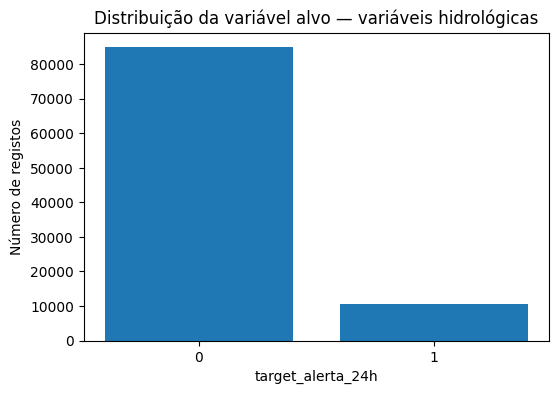

In [30]:
target_hidro_counts = df_hidro["target_alerta_24h"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(target_hidro_counts.index.astype(str), target_hidro_counts.values)
plt.xlabel("target_alerta_24h")
plt.ylabel("Número de registos")
plt.title("Distribuição da variável alvo — variáveis hidrológicas")
plt.show()

In [31]:
cols_excluir_hidro = [
    # Alvo e derivados futuros
    "target_alerta_24h",
    "max_alerta_prox_24h",

    # Informação temporal bruta usada para ordenação/split
    "id_tempo",
    "data_hora",

    # Estado atual calculado diretamente por limiares
    "nivel_alerta",

    # Indicadores mensais excluídos para reduzir risco de data leakage
    # nomes reais das colunas Gold (exclusão robusta caso os indicadores estejam presentes)
    "precipitacao_acumulada",
    "nivel_maximo_periodo",
    "caudal_medio_periodo",
    "num_excedencias_limiar",
    # nomes alternativos (compatibilidade)
    "indicador_precipitacao_acumulada",
    "indicador_nivel_maximo_periodo",
    "indicador_valor_medio_periodo",
    "indicador_num_excedencias_limiar",
]

cols_excluir_hidro = [c for c in cols_excluir_hidro if c in df_hidro.columns]

feature_cols_hidro = [
    c for c in df_hidro.columns
    if c not in cols_excluir_hidro
]

print("Colunas excluídas na experiência hidrológica:")
display(cols_excluir_hidro)

print("\nNúmero de features candidatas:", len(feature_cols_hidro))
display(feature_cols_hidro)

Colunas excluídas na experiência hidrológica:


['target_alerta_24h',
 'max_alerta_prox_24h',
 'id_tempo',
 'data_hora',
 'nivel_alerta']


Número de features candidatas: 42


['codigo_estacao',
 'tipo_variavel',
 'valor_observado',
 'nome_estacao',
 'tipo_estacao',
 'unidade',
 'id_estacao',
 'id_variavel',
 'id_localizacao',
 'bacia',
 'concelho',
 'distrito',
 'zona_risco',
 'tipo_zona',
 'ano',
 'mes',
 'trimestre',
 'semana',
 'hora',
 'estacao_ano',
 'variacao_valor',
 'dia_mes',
 'dia_semana',
 'fim_semana',
 'hora_sin',
 'hora_cos',
 'mes_sin',
 'mes_cos',
 'valor_observado_lag_1h',
 'valor_observado_lag_3h',
 'valor_observado_lag_6h',
 'valor_observado_lag_12h',
 'valor_observado_lag_24h',
 'valor_observado_media_movel_3h',
 'valor_observado_max_movel_3h',
 'valor_observado_media_movel_6h',
 'valor_observado_max_movel_6h',
 'valor_observado_media_movel_12h',
 'valor_observado_max_movel_12h',
 'valor_observado_media_movel_24h',
 'valor_observado_max_movel_24h',
 'variacao_valor_lag_1h']

In [32]:
datas_ordenadas_hidro = np.sort(df_hidro["data_hora"].unique())

cutoff_idx_hidro = int(len(datas_ordenadas_hidro) * 0.80)
cutoff_date_hidro = datas_ordenadas_hidro[cutoff_idx_hidro]

train_hidro_df = df_hidro[df_hidro["data_hora"] < cutoff_date_hidro].copy()
test_hidro_df = df_hidro[df_hidro["data_hora"] >= cutoff_date_hidro].copy()

X_train_hidro = train_hidro_df[feature_cols_hidro].copy()
y_train_hidro = train_hidro_df["target_alerta_24h"].copy()

X_test_hidro = test_hidro_df[feature_cols_hidro].copy()
y_test_hidro = test_hidro_df["target_alerta_24h"].copy()

print("Data de corte:", cutoff_date_hidro)
print("Treino:", X_train_hidro.shape)
print("Teste:", X_test_hidro.shape)

print("\nDistribuição do alvo no treino:")
display(y_train_hidro.value_counts().sort_index())
display((y_train_hidro.value_counts(normalize=True).sort_index() * 100).round(2))

print("\nDistribuição do alvo no teste:")
display(y_test_hidro.value_counts().sort_index())
display((y_test_hidro.value_counts(normalize=True).sort_index() * 100).round(2))

Data de corte: 2025-03-24T10:00:00.000000
Treino: (77289, 42)
Teste: (18174, 42)

Distribuição do alvo no treino:


target_alerta_24h
0    70587
1     6702
Name: count, dtype: int64

target_alerta_24h
0    91.33
1     8.67
Name: proportion, dtype: float64


Distribuição do alvo no teste:


target_alerta_24h
0    14282
1     3892
Name: count, dtype: int64

target_alerta_24h
0    78.58
1    21.42
Name: proportion, dtype: float64

In [33]:
numeric_features_hidro = X_train_hidro.select_dtypes(
    include=["int64", "int32", "float64", "float32"]
).columns.tolist()

categorical_features_hidro = X_train_hidro.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Features numéricas:", len(numeric_features_hidro))
display(numeric_features_hidro)

print("\nFeatures categóricas:", len(categorical_features_hidro))
display(categorical_features_hidro)

Features numéricas: 31


/var/folders/_h/_pwmhsdx6cq6yj6lwr5xpmvc0000gn/T/ipykernel_44137/680623525.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features_hidro = X_train_hidro.select_dtypes(


['valor_observado',
 'id_estacao',
 'id_variavel',
 'id_localizacao',
 'ano',
 'mes',
 'trimestre',
 'semana',
 'hora',
 'variacao_valor',
 'dia_mes',
 'dia_semana',
 'fim_semana',
 'hora_sin',
 'hora_cos',
 'mes_sin',
 'mes_cos',
 'valor_observado_lag_1h',
 'valor_observado_lag_3h',
 'valor_observado_lag_6h',
 'valor_observado_lag_12h',
 'valor_observado_lag_24h',
 'valor_observado_media_movel_3h',
 'valor_observado_max_movel_3h',
 'valor_observado_media_movel_6h',
 'valor_observado_max_movel_6h',
 'valor_observado_media_movel_12h',
 'valor_observado_max_movel_12h',
 'valor_observado_media_movel_24h',
 'valor_observado_max_movel_24h',
 'variacao_valor_lag_1h']


Features categóricas: 11


['codigo_estacao',
 'tipo_variavel',
 'nome_estacao',
 'tipo_estacao',
 'unidade',
 'bacia',
 'concelho',
 'distrito',
 'zona_risco',
 'tipo_zona',
 'estacao_ano']

In [34]:
numeric_transformer_hidro = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer_hidro = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor_hidro = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_hidro, numeric_features_hidro),
        ("cat", categorical_transformer_hidro, categorical_features_hidro),
    ],
    remainder="drop",
)


===== Baseline hidrológico — classe maioritária =====
              precision    recall  f1-score   support

           0       0.79      1.00      0.88     14282
           1       0.00      0.00      0.00      3892

    accuracy                           0.79     18174
   macro avg       0.39      0.50      0.44     18174
weighted avg       0.62      0.79      0.69     18174



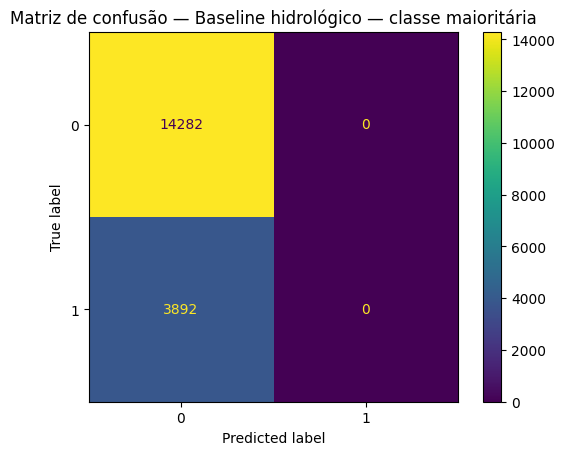

In [35]:
baseline_hidro = Pipeline(steps=[
    ("preprocessor", preprocessor_hidro),
    ("classifier", DummyClassifier(strategy="most_frequent")),
])

baseline_hidro.fit(X_train_hidro, y_train_hidro)

resultados_hidro = []
resultados_hidro.append(
    avaliar_modelo(
        "Baseline hidrológico — classe maioritária",
        baseline_hidro,
        X_test_hidro,
        y_test_hidro
    )
)


===== Regressão Logística hidrológica =====
              precision    recall  f1-score   support

           0       0.96      0.89      0.93     14282
           1       0.69      0.88      0.77      3892

    accuracy                           0.89     18174
   macro avg       0.83      0.89      0.85     18174
weighted avg       0.91      0.89      0.89     18174



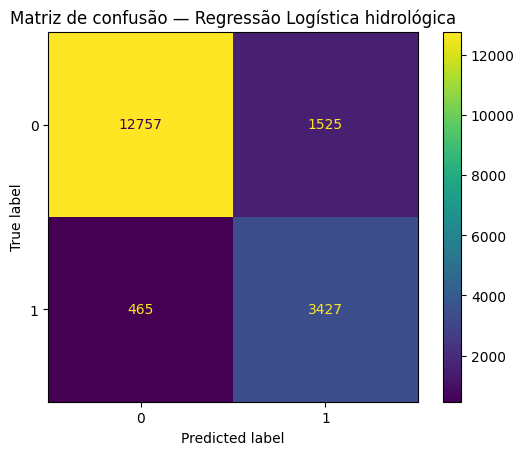

In [36]:
log_reg_hidro = Pipeline(steps=[
    ("preprocessor", preprocessor_hidro),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
])

log_reg_hidro.fit(X_train_hidro, y_train_hidro)

resultados_hidro.append(
    avaliar_modelo(
        "Regressão Logística hidrológica",
        log_reg_hidro,
        X_test_hidro,
        y_test_hidro
    )
)


===== Árvore de Decisão hidrológica =====
              precision    recall  f1-score   support

           0       0.97      0.87      0.91     14282
           1       0.65      0.89      0.75      3892

    accuracy                           0.87     18174
   macro avg       0.81      0.88      0.83     18174
weighted avg       0.90      0.87      0.88     18174



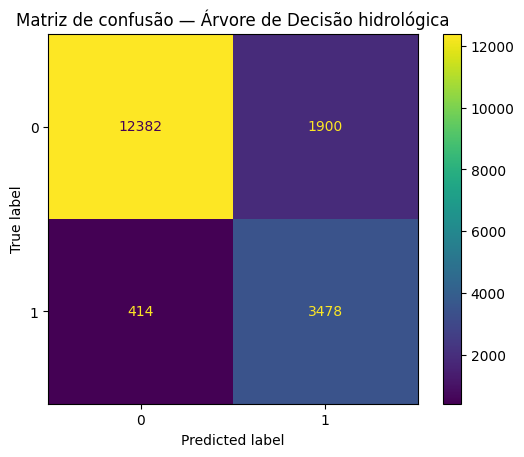

In [37]:
decision_tree_hidro = Pipeline(steps=[
    ("preprocessor", preprocessor_hidro),
    ("classifier", DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=50,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
])

decision_tree_hidro.fit(X_train_hidro, y_train_hidro)

resultados_hidro.append(
    avaliar_modelo(
        "Árvore de Decisão hidrológica",
        decision_tree_hidro,
        X_test_hidro,
        y_test_hidro
    )
)


===== Random Forest hidrológica =====
              precision    recall  f1-score   support

           0       0.97      0.92      0.94     14282
           1       0.75      0.88      0.81      3892

    accuracy                           0.91     18174
   macro avg       0.86      0.90      0.88     18174
weighted avg       0.92      0.91      0.91     18174



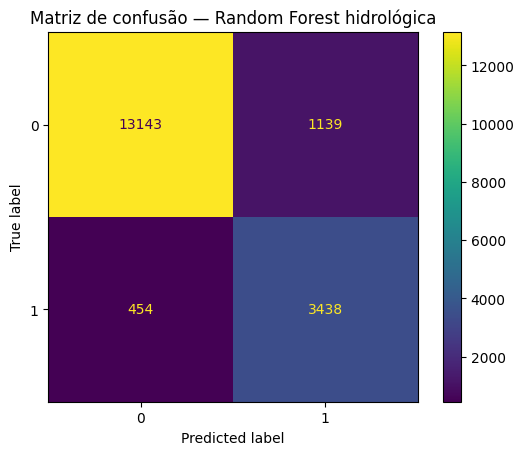

In [38]:
random_forest_hidro = Pipeline(steps=[
    ("preprocessor", preprocessor_hidro),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=25,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )),
])

random_forest_hidro.fit(X_train_hidro, y_train_hidro)

resultados_hidro.append(
    avaliar_modelo(
        "Random Forest hidrológica",
        random_forest_hidro,
        X_test_hidro,
        y_test_hidro
    )
)

###  Melhor modelo hidrológico

Na experiência hidrológica, a Random Forest apresenta o melhor F1-score e mantém recall elevado.

Isto significa que o modelo consegue detetar uma grande parte dos alertas futuros, mantendo um equilíbrio aceitável entre falsos positivos e falsos negativos.

Como o problema está associado a risco, o recall é especialmente relevante: um falso negativo significa que o sistema não antecipou um alerta futuro.


In [39]:
resultados_hidro_df = pd.DataFrame(resultados_hidro)
resultados_hidro_df = resultados_hidro_df.sort_values("f1", ascending=False)

display(resultados_hidro_df.round(4))

,modelo,accuracy,precision,recall,f1,roc_auc,average_precision
3,Random Forest hidrológica,0.9123,0.7511,0.8834,0.8119,0.9741,0.9484
1,Regressão Logística hidrológica,0.8905,0.6920,0.8805,0.7750,0.9605,0.9320
2,Árvore de Decisão hidrológica,0.8727,0.6467,0.8936,0.7504,0.9506,0.9227
0,Baseline hidrológico — classe maioritária,0.7858,0.0000,0.0000,0.0000,0.5000,0.2142


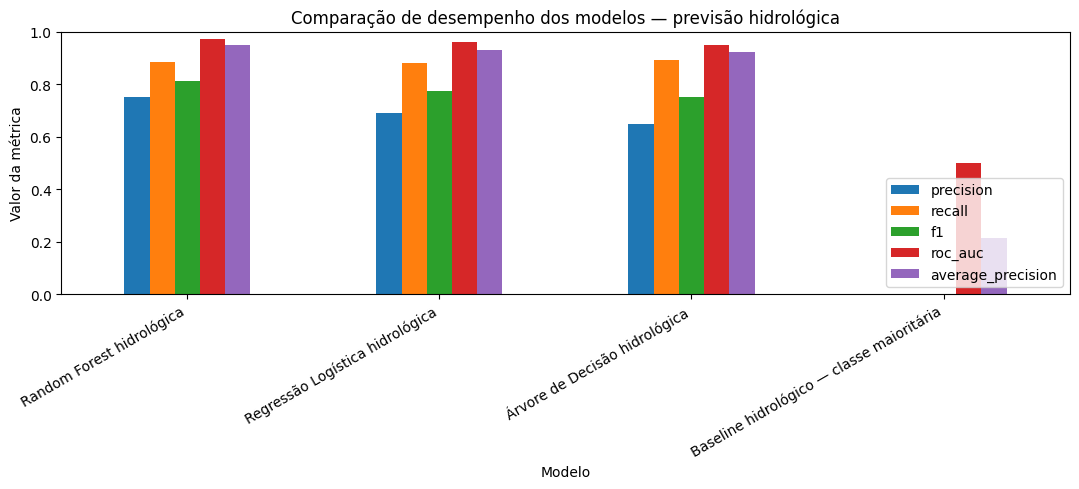

In [40]:
metricas_plot_hidro = ["precision", "recall", "f1", "roc_auc", "average_precision"]

plot_hidro_df = resultados_hidro_df.set_index("modelo")[metricas_plot_hidro]

plot_hidro_df.plot(kind="bar", figsize=(11, 5))
plt.title("Comparação de desempenho dos modelos — previsão hidrológica")
plt.ylabel("Valor da métrica")
plt.xlabel("Modelo")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [41]:
resultados_exp1 = resultados_df.copy()
resultados_exp1["experiencia"] = "Experiência 1 — todas as variáveis"

resultados_exp2 = resultados_hidro_df.copy()
resultados_exp2["experiencia"] = "Experiência 2 — variáveis hidrológicas"

comparacao_experiencias = pd.concat(
    [resultados_exp1, resultados_exp2],
    ignore_index=True
)

comparacao_experiencias = comparacao_experiencias[
    [
        "experiencia",
        "modelo",
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc",
        "average_precision",
    ]
].sort_values(["experiencia", "f1"], ascending=[True, False])

display(comparacao_experiencias.round(4))

,experiencia,modelo,accuracy,precision,recall,f1,roc_auc,average_precision
0,Experiência 1 — todas as variáveis,Random Forest,0.9067,0.6326,0.8606,0.7292,0.9567,0.9064
1,Experiência 1 — todas as variáveis,Regressão Logística,0.8697,0.5323,0.8852,0.6648,0.9342,0.8927
2,Experiência 1 — todas as variáveis,Árvore de Decisão,0.5489,0.2299,0.8896,0.3653,0.9021,0.8660
3,Experiência 1 — todas as variáveis,Baseline — classe maioritária,0.8541,0.0000,0.0000,0.0000,0.5000,0.1459
4,Experiência 2 — variáveis hidrológicas,Random Forest hidrológica,0.9123,0.7511,0.8834,0.8119,0.9741,0.9484
5,Experiência 2 — variáveis hidrológicas,Regressão Logística hidrológica,0.8905,0.6920,0.8805,0.7750,0.9605,0.9320
6,Experiência 2 — variáveis hidrológicas,Árvore de Decisão hidrológica,0.8727,0.6467,0.8936,0.7504,0.9506,0.9227
7,Experiência 2 — variáveis hidrológicas,Baseline hidrológico — classe maioritária,0.7858,0.0000,0.0000,0.0000,0.5000,0.2142


##  Comparação entre a experiência completa e a experiência hidrológica

A comparação entre experiências permite justificar a escolha da formulação final.

A primeira experiência confirma que existe sinal preditivo no conjunto completo de variáveis.

A segunda experiência mostra uma formulação mais focada no estado hidrológico do sistema. Como esta versão apresenta melhor equilíbrio entre F1-score e recall, foi escolhida como formulação final.

In [42]:
melhor_nome_hidro = resultados_hidro_df.iloc[0]["modelo"]

modelos_hidro = {
    "Baseline hidrológico — classe maioritária": baseline_hidro,
    "Regressão Logística hidrológica": log_reg_hidro,
    "Árvore de Decisão hidrológica": decision_tree_hidro,
    "Random Forest hidrológica": random_forest_hidro,
}

melhor_modelo_hidro = modelos_hidro[melhor_nome_hidro]

print("Melhor modelo hidrológico segundo F1:", melhor_nome_hidro)
display(resultados_hidro_df.iloc[0])

Melhor modelo hidrológico segundo F1: Random Forest hidrológica


modelo               Random Forest hidrológica
accuracy                              0.912347
precision                             0.751147
recall                                 0.88335
f1                                    0.811902
roc_auc                                0.97411
average_precision                     0.948444
Name: 3, dtype: object

In [43]:
predicoes_hidro_df = test_hidro_df.copy()
predicoes_hidro_df["pred_target_alerta_24h"] = melhor_modelo_hidro.predict(X_test_hidro)

if hasattr(melhor_modelo_hidro, "predict_proba"):
    predicoes_hidro_df["prob_alerta_24h"] = melhor_modelo_hidro.predict_proba(X_test_hidro)[:, 1]
else:
    predicoes_hidro_df["prob_alerta_24h"] = np.nan

display(
    predicoes_hidro_df[
        [
            "data_hora",
            "codigo_estacao",
            "nome_estacao",
            "tipo_variavel",
            "valor_observado",
            "target_alerta_24h",
            "pred_target_alerta_24h",
            "prob_alerta_24h",
        ]
    ].head(30)
)

,data_hora,codigo_estacao,nome_estacao,tipo_variavel,valor_observado,target_alerta_24h,pred_target_alerta_24h,prob_alerta_24h
14338,2025-03-24 10:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,122.80,1,1,1.000000
14339,2025-03-24 11:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,122.85,1,1,1.000000
14340,2025-03-24 12:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,122.89,1,1,1.000000
14341,2025-03-24 13:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,122.93,1,1,1.000000
14342,2025-03-24 14:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,122.97,1,1,1.000000
14343,2025-03-24 15:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,123.02,1,1,1.000000
14344,2025-03-24 16:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,123.06,1,1,1.000000
14345,2025-03-24 17:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,123.09,1,1,1.000000
14346,2025-03-24 18:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,123.11,1,1,1.000000
14347,2025-03-24 19:00:00,11H/01A,ALBUFEIRA DA AGUIEIRA,COTA_ALBUFEIRA,123.10,1,1,1.000000


In [44]:
avaliacao_por_variavel = []

for variavel, grupo in predicoes_hidro_df.groupby("tipo_variavel"):
    y_true_var = grupo["target_alerta_24h"]
    y_pred_var = grupo["pred_target_alerta_24h"]

    if len(y_true_var.unique()) < 2:
        roc_auc_var = np.nan
        avg_precision_var = np.nan
    else:
        roc_auc_var = roc_auc_score(y_true_var, grupo["prob_alerta_24h"])
        avg_precision_var = average_precision_score(y_true_var, grupo["prob_alerta_24h"])

    avaliacao_por_variavel.append({
        "tipo_variavel": variavel,
        "n_registos": len(grupo),
        "n_alertas_reais": int(y_true_var.sum()),
        "accuracy": accuracy_score(y_true_var, y_pred_var),
        "precision": precision_score(y_true_var, y_pred_var, zero_division=0),
        "recall": recall_score(y_true_var, y_pred_var, zero_division=0),
        "f1": f1_score(y_true_var, y_pred_var, zero_division=0),
        "roc_auc": roc_auc_var,
        "average_precision": avg_precision_var,
    })

avaliacao_por_variavel_df = pd.DataFrame(avaliacao_por_variavel)
display(avaliacao_por_variavel_df.round(4))

,tipo_variavel,n_registos,n_alertas_reais,accuracy,precision,recall,f1,roc_auc,average_precision
0,COTA_ALBUFEIRA,2467,2396,0.9988,0.9992,0.9996,0.9994,1.0000,1.0000
1,NIVEL_HIDROMETRICO,15707,1496,0.8988,0.4784,0.6972,0.5675,0.9325,0.7817


### Desempenho por variável 

A avaliação por variável mostra que o desempenho global não é uniforme. A **cota de albufeira** apresenta desempenho muito elevado, enquanto o **nível hidrométrico** é mais difícil de prever. Isto é importante porque impede uma interpretação demasiado otimista do resultado global. O modelo tem bom desempenho geral, mas a sua fiabilidade varia conforme a variável analisada.

---


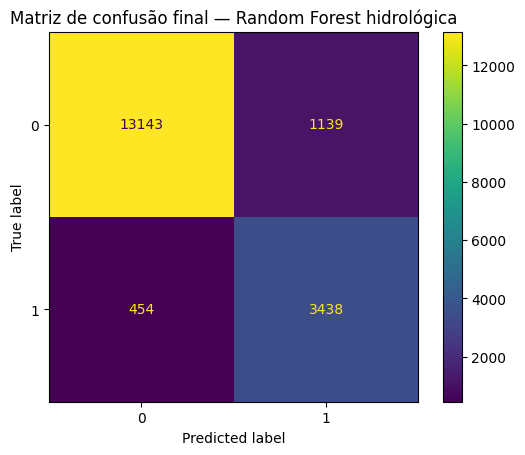

TN: 13143
FP: 1139
FN: 454
TP: 3438


In [45]:
y_pred_hidro_final = predicoes_hidro_df["pred_target_alerta_24h"]

cm_hidro = confusion_matrix(y_test_hidro, y_pred_hidro_final)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_hidro)
disp.plot()
plt.title(f"Matriz de confusão final — {melhor_nome_hidro}")
plt.show()

tn, fp, fn, tp = cm_hidro.ravel()

print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

## Matriz de confusão

A matriz de confusão permite interpretar os erros do modelo final. 

Os **falsos positivos** correspondem a situações em que o modelo prevê alerta, mas o alerta não ocorre. Estes casos podem gerar alarmes desnecessários. Os **falsos negativos** são mais críticos, porque representam situações em que havia alerta futuro e o modelo não o antecipou. 

Num sistema de apoio à decisão para risco de cheia, é preferível manter recall elevado, mesmo que isso implique aceitar alguns falsos positivos.

---

##  Importância das variáveis

Nesta parte analisamos quais as features mais usadas pela Random Forest.

,feature,importance
0,valor_observado,0.114939
23,valor_observado_max_movel_3h,0.111694
22,valor_observado_media_movel_3h,0.103244
24,valor_observado_media_movel_6h,0.084713
17,valor_observado_lag_1h,0.080852
25,valor_observado_max_movel_6h,0.078739
18,valor_observado_lag_3h,0.048581
27,valor_observado_max_movel_12h,0.048167
29,valor_observado_max_movel_24h,0.039109
19,valor_observado_lag_6h,0.021016


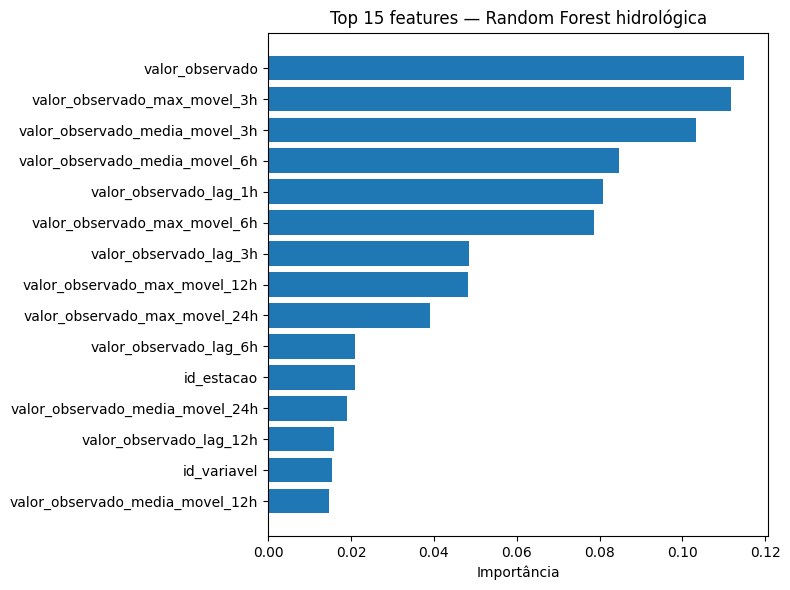

In [46]:
def obter_nomes_features_generico(preprocessor_obj, numeric_cols, categorical_cols) -> list[str]:
    nomes = []

    if numeric_cols:
        nomes.extend(numeric_cols)

    if categorical_cols:
        onehot = preprocessor_obj.named_transformers_["cat"].named_steps["onehot"]
        cat_names = onehot.get_feature_names_out(categorical_cols).tolist()
        nomes.extend(cat_names)

    return nomes


classifier_hidro = melhor_modelo_hidro.named_steps["classifier"]

if hasattr(classifier_hidro, "feature_importances_"):
    preprocessor_hidro_fitted = melhor_modelo_hidro.named_steps["preprocessor"]

    feature_names_hidro = obter_nomes_features_generico(
        preprocessor_hidro_fitted,
        numeric_features_hidro,
        categorical_features_hidro
    )

    importances_hidro = classifier_hidro.feature_importances_

    importancias_hidro_df = pd.DataFrame({
        "feature": feature_names_hidro,
        "importance": importances_hidro,
    }).sort_values("importance", ascending=False)

    display(importancias_hidro_df.head(20))

    top_importancias_hidro = importancias_hidro_df.head(15).sort_values("importance")

    plt.figure(figsize=(8, 6))
    plt.barh(top_importancias_hidro["feature"], top_importancias_hidro["importance"])
    plt.xlabel("Importância")
    plt.title(f"Top 15 features — {melhor_nome_hidro}")
    plt.tight_layout()
    plt.show()

else:
    print(f"O modelo {melhor_nome_hidro} não disponibiliza feature_importances_.")

As variáveis mais importantes tendem a estar associadas ao valor observado recente, lags, médias móveis e máximos móveis.

Isto faz sentido no domínio: para prever se haverá alerta nas próximas 24 horas, o comportamento recente da estação e da variável é muito relevante.

---

In [47]:
os.makedirs(CSV_DIR, exist_ok=True)

resultados_hidro_df.to_csv(
    f"{CSV_DIR}/resultados_modelos_previsao_hidrologica_24h.csv",
    index=False
)

predicoes_hidro_df[
    [
        "data_hora",
        "codigo_estacao",
        "nome_estacao",
        "tipo_variavel",
        "valor_observado",
        "target_alerta_24h",
        "pred_target_alerta_24h",
        "prob_alerta_24h",
    ]
].to_csv(
    f"{CSV_DIR}/predicoes_teste_alerta_hidrologico_24h.csv",
    index=False
)

avaliacao_por_variavel_df.to_csv(
    f"{CSV_DIR}/avaliacao_por_variavel_hidrologica_24h.csv",
    index=False
)

comparacao_experiencias.to_csv(
    f"{CSV_DIR}/comparacao_experiencias_previsao_24h.csv",
    index=False
)

print("Ficheiros CSV guardados em:", CSV_DIR)

Ficheiros CSV guardados em: ../outputs/previsao/csv


## Conclusão final da demonstração 

A demonstração mostra que a camada Gold pode ser usada não só para dashboards, mas também para uma componente preditiva. O processo começa com medições validadas da `Fact_Medicoes`, cria um alvo de alerta a 24 horas, constrói features temporais, separa treino e teste de forma temporal e compara vários modelos. 

A formulação final usa variáveis hidrológicas e escolhe a Random Forest, por apresentar o melhor equilíbrio entre F1-score e recall. Ainda assim, esta componente deve ser interpretada como prova de conceito. O modelo prevê alerta hidrológico futuro com base nos dados disponíveis, mas não substitui validação operacional, integração de previsões meteorológicas externas nem confirmação oficial de eventos de cheia.

In [48]:
print("Síntese final — Experiência 2")
print("-----------------------------")
print(f"Dataset hidrológico: {df_hidro.shape[0]} registos e {df_hidro.shape[1]} colunas.")
print(f"Período analisado: {df_hidro['data_hora'].min()} a {df_hidro['data_hora'].max()}.")
print("Variáveis consideradas:", ", ".join(variaveis_hidrologicas))
print("Horizonte de previsão: 24 horas.")
print("Target positivo: existência de nivel_alerta >= 1 nas próximas 24 horas.")

print("\nDistribuição do target hidrológico:")
display(df_hidro["target_alerta_24h"].value_counts().sort_index())
display((df_hidro["target_alerta_24h"].value_counts(normalize=True).sort_index() * 100).round(2))

print("\nComparação dos modelos hidrológicos:")
display(resultados_hidro_df.round(4))

print("\nMelhor modelo hidrológico segundo F1:")
display(resultados_hidro_df.iloc[0])

print("\nAvaliação por variável hidrológica:")
display(avaliacao_por_variavel_df.round(4))

Síntese final — Experiência 2
-----------------------------
Dataset hidrológico: 95463 registos e 47 colunas.
Período analisado: 2020-10-01 00:00:00 a 2026-05-18 15:00:00.
Variáveis consideradas: COTA_ALBUFEIRA, NIVEL_HIDROMETRICO
Horizonte de previsão: 24 horas.
Target positivo: existência de nivel_alerta >= 1 nas próximas 24 horas.

Distribuição do target hidrológico:


target_alerta_24h
0    84869
1    10594
Name: count, dtype: int64

target_alerta_24h
0    88.9
1    11.1
Name: proportion, dtype: float64


Comparação dos modelos hidrológicos:


,modelo,accuracy,precision,recall,f1,roc_auc,average_precision
3,Random Forest hidrológica,0.9123,0.7511,0.8834,0.8119,0.9741,0.9484
1,Regressão Logística hidrológica,0.8905,0.6920,0.8805,0.7750,0.9605,0.9320
2,Árvore de Decisão hidrológica,0.8727,0.6467,0.8936,0.7504,0.9506,0.9227
0,Baseline hidrológico — classe maioritária,0.7858,0.0000,0.0000,0.0000,0.5000,0.2142



Melhor modelo hidrológico segundo F1:


modelo               Random Forest hidrológica
accuracy                              0.912347
precision                             0.751147
recall                                 0.88335
f1                                    0.811902
roc_auc                                0.97411
average_precision                     0.948444
Name: 3, dtype: object


Avaliação por variável hidrológica:


,tipo_variavel,n_registos,n_alertas_reais,accuracy,precision,recall,f1,roc_auc,average_precision
0,COTA_ALBUFEIRA,2467,2396,0.9988,0.9992,0.9996,0.9994,1.0000,1.0000
1,NIVEL_HIDROMETRICO,15707,1496,0.8988,0.4784,0.6972,0.5675,0.9325,0.7817


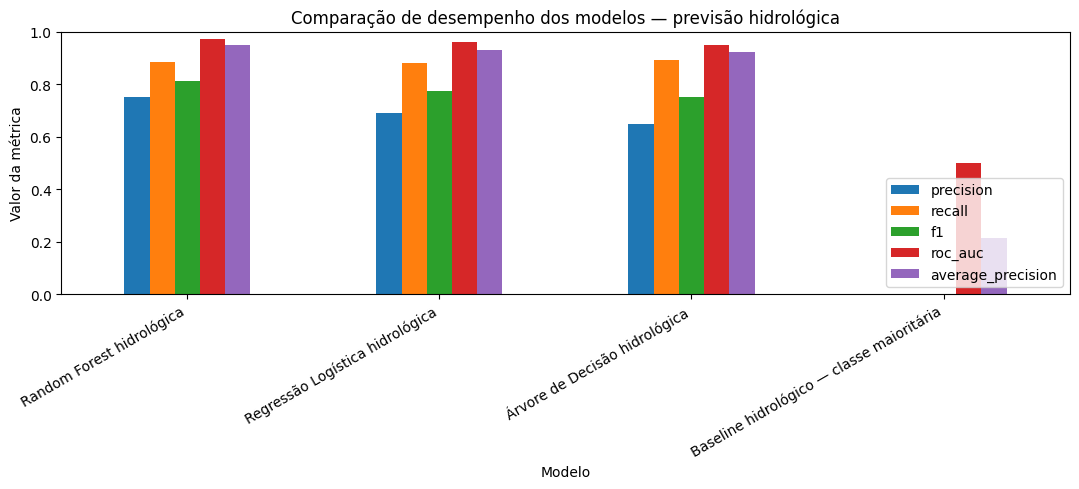

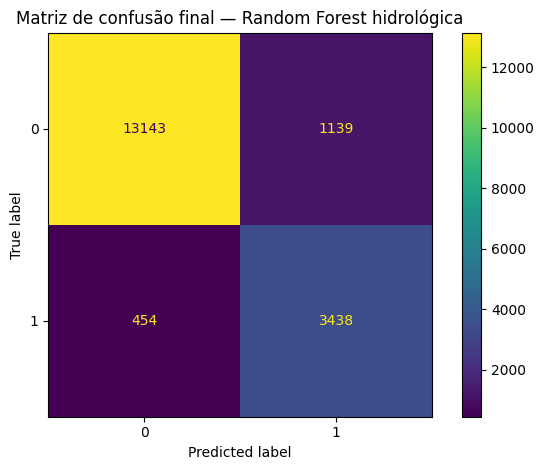

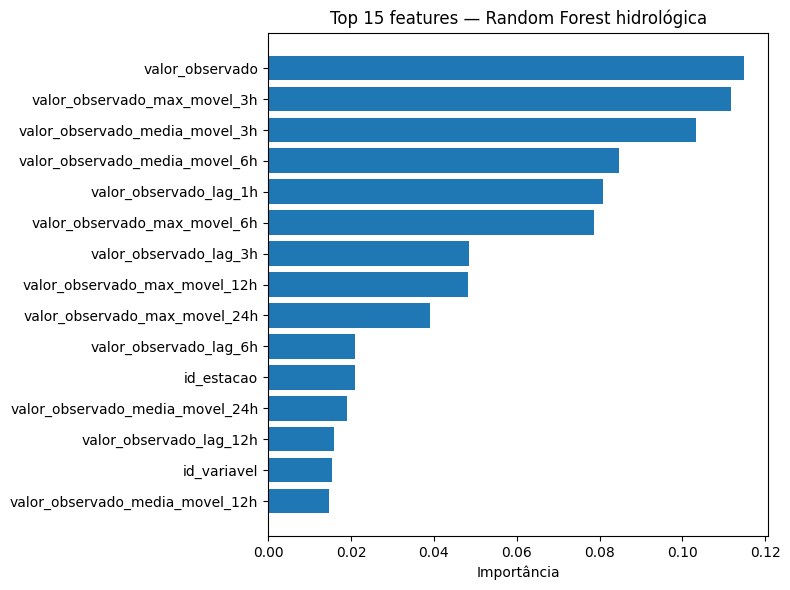

Figuras guardadas em ../outputs/previsao/figuras


In [49]:
os.makedirs(FIGURES_DIR, exist_ok=True)

# Gráfico de comparação dos modelos hidrológicos
plot_hidro_df = resultados_hidro_df.set_index("modelo")[
    ["precision", "recall", "f1", "roc_auc", "average_precision"]
]

ax = plot_hidro_df.plot(kind="bar", figsize=(11, 5))
plt.title("Comparação de desempenho dos modelos — previsão hidrológica")
plt.ylabel("Valor da métrica")
plt.xlabel("Modelo")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/comparacao_modelos_hidrologicos.png", dpi=300, bbox_inches="tight")
plt.show()

# Matriz de confusão final
disp = ConfusionMatrixDisplay(confusion_matrix=cm_hidro)
disp.plot()
plt.title(f"Matriz de confusão final — {melhor_nome_hidro}")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/matriz_confusao_random_forest_hidrologica.png", dpi=300, bbox_inches="tight")
plt.show()

# Importância das features, se existir
if "importancias_hidro_df" in globals():
    top_importancias_hidro = importancias_hidro_df.head(15).sort_values("importance")

    plt.figure(figsize=(8, 6))
    plt.barh(top_importancias_hidro["feature"], top_importancias_hidro["importance"])
    plt.xlabel("Importância")
    plt.title(f"Top 15 features — {melhor_nome_hidro}")
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/importancia_features_random_forest_hidrologica.png", dpi=300, bbox_inches="tight")
    plt.show()

print("Figuras guardadas em", FIGURES_DIR)